Example 8: Nanoparticle Size Distribution from UV-Vis (Population Balance)

A port of the standalone ``qd_growth_uvvis.py`` demo onto the new
:class:`kipetax.PopulationBalanceModel`. This is the class of problem
``ReactionModel`` cannot express: the state is not a finite species list but a
distribution N(r, t) over particle radius, and the observation is an integral
over that distribution.

Quantum-dot growth. A sectional population balance carries N(r, t): a
prescribed nucleation burst seeds particles at a small radius, diffusion-limited
growth advects them up the size axis, and a monomer mass balance couples every
section (the monomer left in solution is what has not yet condensed onto
particles). The ensemble is watched by UV-Vis through a quantum-confinement
kernel: a particle of radius r has an exciton peak at
lambda_peak(r) = 1240 / (E_bulk + a / r^2), so the spectrum is an integral over
the size distribution weighted by r^3. Recovering N(r) from one spectrum is a
Fredholm integral of the first kind, ill-posed, which is exactly why UV-Vis and
DLS sizing need regularization.

The mechanism IS the regularization. Fitting the two growth parameters
(k_g, A_nuc) to the whole UV-Vis time series ties every time point together and
reconstructs N(r, t), while a naive per-spectrum non-negative inversion, which
sees each spectrum in isolation, collapses. The population balance is integrated
by a differentiable fixed-step upwind Euler scheme (positivity-preserving for
advection), and the fit differentiates through it with JAX autodiff.

NOTE: all data here is SYNTHETIC, generated by the model below. Every radius,
rate, and spectrum comes from the forward model; nothing is measured.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import os

## Setup: helper functions and synthetic-data generators

These are lifted verbatim from the example script (`kipetax/examples/Ex_8_qd_growth_uvvis.py`).

In [2]:
import numpy as np
import jax.numpy as jnp

from kipetax import PopulationBalanceModel

# ── Grid and constants (from the source demo) ──
K = 45
R = np.linspace(0.8, 6.0, K)          # particle radius, nm
DR = float(R[1] - R[0])
LAM = np.linspace(400.0, 720.0, 120)  # wavelength, nm

M0, MEQ, RSTAR, CVOL = 1.0, 0.02, 0.9, 0.9
E_BULK, A_CONF, WIDTH = 1.74, 0.96, 32.0
T0, TAU = 2.0, 0.8
TF, NT = 40.0, 1600
JSTAR = int(np.argmin(np.abs(R - RSTAR)))

KG_TRUE, ANUC_TRUE = 0.018, 0.020

# Quantum-confinement kernel: size ruler + r^3 volume weighting.
LPEAK = 1240.0 / (E_BULK + A_CONF / R ** 2)                       # (K,)
KERNEL = (R ** 3)[None, :] * np.exp(-(LAM[:, None] - LPEAK[None, :]) ** 2
                                    / (2 * WIDTH ** 2))           # (n_lam, K)

T_OBS = np.array([1.5, 2.5, 3.5, 5, 7, 10, 14, 20, 28, 40.0])
IDX_OBS = np.clip((T_OBS / TF * NT).astype(int), 0, NT - 1)

_R = jnp.asarray(R)
_KERNEL = jnp.asarray(KERNEL)
_IDX = jnp.asarray(IDX_OBS)

def step(N, t, p):
    """Sectional PBE right-hand side (upwind advection + nucleation source)."""
    kg, anuc = p['kg'], p['anuc']
    # Monomer mass balance -> supersaturation gates growth.
    m = jnp.maximum(M0 - CVOL * jnp.sum(N * _R ** 3) * DR, MEQ)
    S = m / MEQ
    G = jnp.where(S > 1.0, kg / _R * (S - 1.0), 0.0)
    # Upwind advection (G > 0, backward difference).
    F = G * N
    dN = -F / DR
    dN = dN.at[1:].add(F[:-1] / DR)
    # Nucleation burst into the seed cell.
    J = anuc * jnp.exp(-(t - T0) ** 2 / (2 * TAU ** 2))
    dN = dN.at[JSTAR].add(J / DR)
    return dN

def observe(history, p):
    """UV-Vis spectra at the observation times: A = (N . DR) @ KERNEL^T."""
    Nsel = history[_IDX]                       # (n_obs, K)
    return (Nsel * DR) @ _KERNEL.T             # (n_obs, n_lam)

def build_model():
    pbm = PopulationBalanceModel('qd_growth')
    pbm.set_coordinate('r', R)
    pbm.parameter('kg', value=0.010, bounds=(1e-3, 0.1))
    pbm.parameter('anuc', value=0.010, bounds=(1e-3, 0.1))
    pbm.set_initial_state(jnp.zeros(K))
    pbm.set_dynamics(step, t_end=TF, nt=NT, scheme='euler')
    pbm.set_observation(observe)
    return pbm

def mean_radius(N_rows):
    """Mass-weighted (r^3) mean radius per row."""
    w = N_rows * R ** 3
    denom = np.maximum(w.sum(axis=1), 1e-12)
    return (w @ R) / denom

## Run the analysis

In [3]:
truth = build_model().simulate({'kg': KG_TRUE, 'anuc': ANUC_TRUE})
A_true = np.asarray(observe(jnp.asarray(truth.state_history),
                            {'kg': KG_TRUE, 'anuc': ANUC_TRUE}))
rng = np.random.default_rng(0)
A_data = A_true + 0.02 * A_true.max() * rng.standard_normal(A_true.shape)

In [4]:
print("Fitting growth kinetics to the UV-Vis time series...")
pbm = build_model()
pbm.add_data(A_data)
ro = pbm.run_opt(verbose=True)

Fitting growth kinetics to the UV-Vis time series...


PopulationBalance fit: status=optimal objective=4.9345e-01 iters=5 |proj grad|=1.01e-03
  kg           = 0.0178224
  anuc         = 0.0201484


/Users/jkitchin/Dropbox/projects/jax-kipet/notebooks/../kipetax/main_modules/population_balance.py:290: OptimizeWarning: Unknown solver options: disp
  res = minimize(scipy_obj, theta0, jac=True, method='L-BFGS-B',


In [5]:
print(f"\n  {'param':8s} {'true':>10s} {'estimated':>12s} {'error%':>9s}")
print(f"  {'-' * 42}")
for name, tv in [('kg', KG_TRUE), ('anuc', ANUC_TRUE)]:
    ev = ro.P[name]
    print(f"  {name:8s} {tv:>10.4f} {ev:>12.4f} {abs(ev - tv) / tv * 100:>8.2f}%")


  param          true    estimated    error%
  ------------------------------------------
  kg           0.0180       0.0178     0.99%
  anuc         0.0200       0.0201     0.74%


In [6]:
# Mechanism-reconstructed distribution vs the naive per-spectrum inversion.
N_true = np.asarray(truth.state_history)[IDX_OBS]
N_fit = ro.state_history[IDX_OBS]
N_naive = PopulationBalanceModel.nnls_inversion(A_data, KERNEL * DR)

In [7]:
r_true = mean_radius(N_true)
rmse_fit = np.sqrt(np.mean((mean_radius(N_fit) - r_true) ** 2))
rmse_naive = np.sqrt(np.mean((mean_radius(N_naive) - r_true) ** 2))

In [8]:
def shape_l1(N):
    row = N[-1] / max(N[-1].sum(), 1e-12)
    return row
l1_fit = np.abs(shape_l1(N_fit) - shape_l1(N_true)).sum()
l1_naive = np.abs(shape_l1(N_naive) - shape_l1(N_true)).sum()

In [9]:
print(f"\n  {'recovery':28s} {'mean-r RMSE (nm)':>16s} {'final-dist L1':>14s}")
print(f"  {'-' * 60}")
print(f"  {'naive per-spectrum inversion':28s} {rmse_naive:>16.3f} {l1_naive:>14.3f}")
print(f"  {'mechanism-constrained fit':28s} {rmse_fit:>16.3f} {l1_fit:>14.3f}")
print("\n  The mechanism ties every time point together and regularizes the "
      "ill-posed inversion.")
ro


  recovery                     mean-r RMSE (nm)  final-dist L1
  ------------------------------------------------------------
  naive per-spectrum inversion            0.203          1.442
  mechanism-constrained fit               0.008          0.015

  The mechanism ties every time point together and regularizes the ill-posed inversion.


## Visualization

Persistent figures: the UV-Vis fit, the recovered particle-size distribution, mean radius over time, and rate-constant recovery -- mechanism versus the naive per-spectrum inversion.

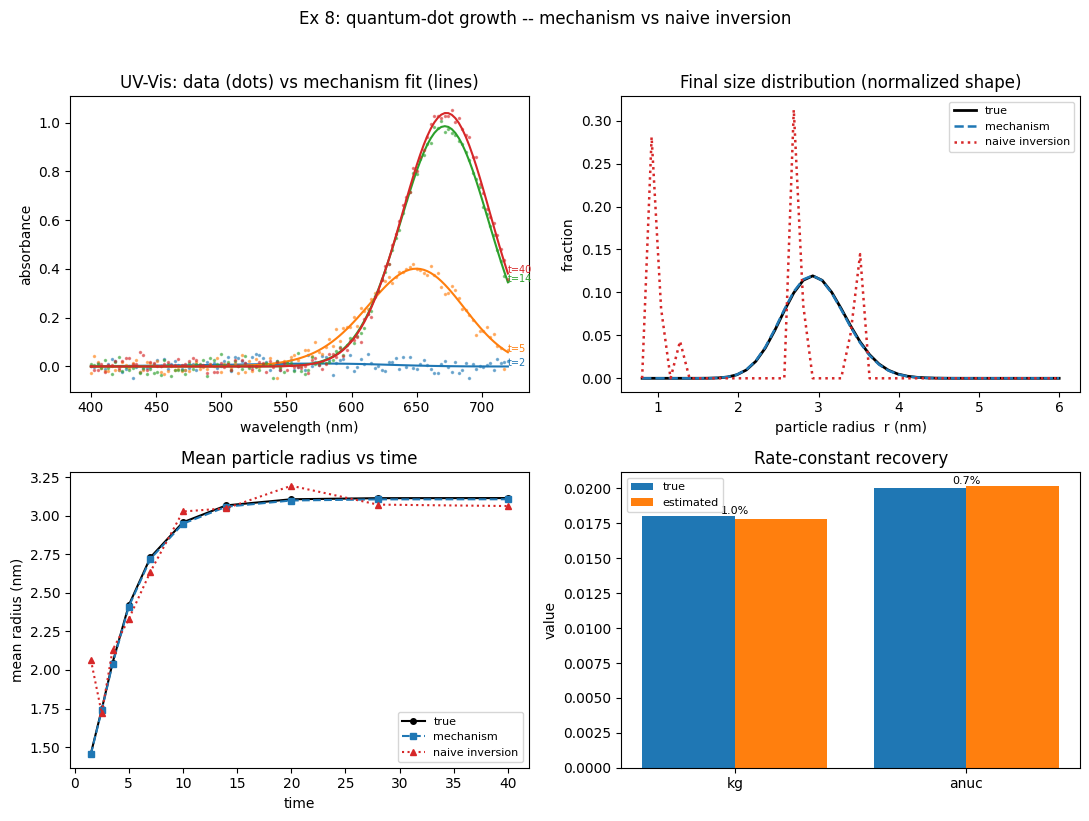

In [10]:
import matplotlib.pyplot as plt

# Mechanism reconstruction of the UV-Vis series from the fitted state history.
A_fit = np.asarray(observe(jnp.asarray(ro.state_history), ro.P))


def _shape(N):
    return N[-1] / max(N[-1].sum(), 1e-12)


fig, ax = plt.subplots(2, 2, figsize=(11, 8))

# (a) UV-Vis: data (dots) vs mechanism fit (lines) at a few observation times.
for s in (0, 3, 6, 9):
    line, = ax[0, 0].plot(LAM, A_fit[s], lw=1.5)
    ax[0, 0].plot(LAM, A_data[s], ls='', marker='.', ms=3, alpha=0.5,
                  color=line.get_color())
    ax[0, 0].annotate(f't={T_OBS[s]:.0f}', (LAM[-1], A_fit[s, -1]),
                      fontsize=7, color=line.get_color())
ax[0, 0].set(title='UV-Vis: data (dots) vs mechanism fit (lines)',
             xlabel='wavelength (nm)', ylabel='absorbance')

# (b) Final particle-size distribution: true / mechanism / naive.
ax[0, 1].plot(R, _shape(N_true), 'k-', lw=2, label='true')
ax[0, 1].plot(R, _shape(N_fit), 'C0--', lw=1.8, label='mechanism')
ax[0, 1].plot(R, _shape(N_naive), 'C3:', lw=1.8, label='naive inversion')
ax[0, 1].set(title='Final size distribution (normalized shape)',
             xlabel='particle radius  r (nm)', ylabel='fraction')
ax[0, 1].legend(fontsize=8)

# (c) Mean particle radius over time: the naive inversion is noisier/biased.
ax[1, 0].plot(T_OBS, mean_radius(N_true), 'k-o', ms=4, label='true')
ax[1, 0].plot(T_OBS, mean_radius(N_fit), 'C0--s', ms=4, label='mechanism')
ax[1, 0].plot(T_OBS, mean_radius(N_naive), 'C3:^', ms=4, label='naive inversion')
ax[1, 0].set(title='Mean particle radius vs time',
             xlabel='time', ylabel='mean radius (nm)')
ax[1, 0].legend(fontsize=8)

# (d) Rate-constant recovery.
names = ['kg', 'anuc']
tv = [KG_TRUE, ANUC_TRUE]
ev = [ro.P['kg'], ro.P['anuc']]
x = np.arange(len(names))
ax[1, 1].bar(x - 0.2, tv, 0.4, label='true')
ax[1, 1].bar(x + 0.2, ev, 0.4, label='estimated')
for xi, (t, e) in enumerate(zip(tv, ev)):
    ax[1, 1].annotate(f'{abs(e - t) / t * 100:.1f}%', (xi, max(t, e)),
                      ha='center', va='bottom', fontsize=8)
ax[1, 1].set_xticks(x)
ax[1, 1].set_xticklabels(names)
ax[1, 1].set(title='Rate-constant recovery', ylabel='value')
ax[1, 1].legend(fontsize=8)

fig.suptitle('Ex 8: quantum-dot growth -- mechanism vs naive inversion', y=1.02)
fig.tight_layout()